# 01 &nbsp;Can we trust this test?

**The test.** In 2008 an online retailer emailed 64,000 recent customers. Each customer was randomly put into one of three groups: **no email**, a **men's email**, or a **women's email**. For two weeks the retailer tracked who visited, who bought, and how much they spent.

**Why start here.** A readout is only as good as the test behind it. Before looking at any lift, two checks: are the groups the size we planned, and do they look alike before the email went out? If either fails, nothing downstream should be trusted.

| Check | Result |
|---|---|
| Group sizes match the plan | Pass |
| Groups look alike before the email | Pass |
| Ready to read results | Yes |

In [1]:
import pandas as pd

from exptoolkit import plots, style
from exptoolkit.checks import COVARIATE_LABELS, sample_ratio_check, standardized_mean_diff
from exptoolkit.data import load_hillstrom

style.use_style()
df = load_hillstrom()
print(f"{len(df):,} customers, {df.shape[1]} columns")

64,000 customers, 14 columns


## 1. Are the groups the size we planned?

The plan was an even three way split. When groups come out noticeably uneven (a *sample ratio mismatch*), it usually means a bug in assignment or tracking, and that bug can bias every result. A chi-square test against the planned split catches it.

In [2]:
srm = sample_ratio_check(df)
sizes = pd.DataFrame({
    "Customers": pd.Series(srm["counts"]),
    "Planned": pd.Series(srm["expected"]),
}).rename(index=style.ARM_LABELS)
sizes["Difference"] = sizes["Customers"] - sizes["Planned"]
print(f"p-value = {srm['p_value']:.2f}")
sizes.style.format("{:,.0f}")

p-value = 0.90


,Customers,Planned,Difference
No email,"21,306","21,333",-27
Men's email,"21,307","21,333",-26
Women's email,"21,387","21,333",54


**Pass.** The groups are within 81 customers of each other and the p-value is 0.90. No sign of a mismatch.

## 2. Do the groups look alike before the email?

If randomization worked, customers in each group should have the same history. The chart compares each email group with the no-email group on every trait we have, using the *standardized mean difference* so traits on different scales can sit on one axis. Anything inside ±0.1 is considered balanced.

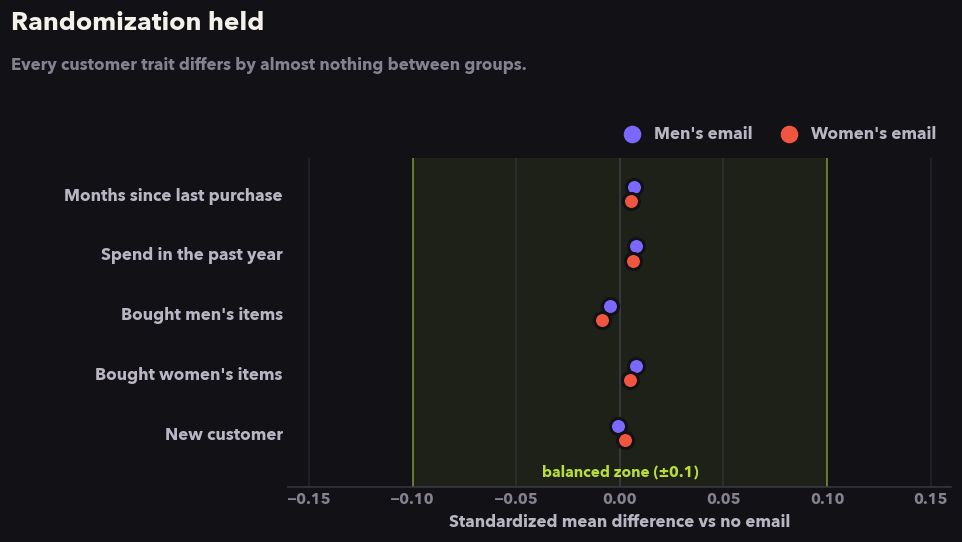

In [3]:
smd = standardized_mean_diff(df, list(COVARIATE_LABELS))
fig, ax = plots.balance_plot(smd, labels=COVARIATE_LABELS)
style.headline(fig, "Randomization held", "Every customer trait differs by almost nothing between groups.")
style.save(fig, "balance")

In [4]:
mix = pd.concat(
    {
        "Channel": pd.crosstab(df["arm"], df["channel"], normalize="index"),
        "Area": pd.crosstab(df["arm"], df["zip_code"].replace({"Surburban": "Suburban"}), normalize="index"),
    },
    axis=1,
).rename(index=style.ARM_LABELS)
mix.style.format("{:.1%}")

**Pass.** The largest difference on any trait is under 0.01, ten times smaller than the threshold, and purchase channel and area type split almost identically. Differences in outcomes can be read as effects of the email.

## 3. A first look at outcomes

Group averages with 95% intervals. The formal readout, with lift, multiple-comparison handling and dollars, comes later in the toolkit.

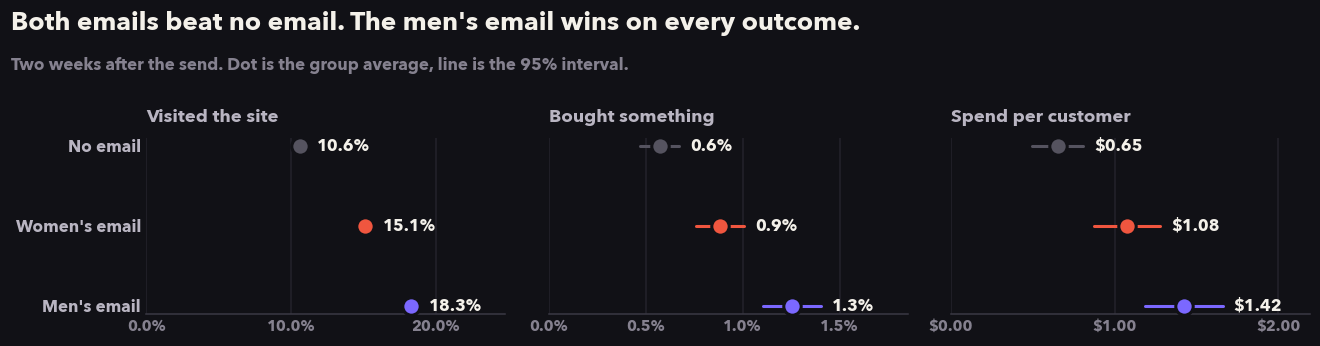

In [5]:
pct = lambda v: f"{100 * v:.1f}%"
fig, axes = plots.group_means_plot(df, {
    "visit": ("Visited the site", pct),
    "conversion": ("Bought something", pct),
    "spend": ("Spend per customer", lambda v: f"${v:.2f}"),
})
style.headline(
    fig,
    "Both emails beat no email. The men's email wins on every outcome.",
    "Two weeks after the send. Dot is the group average, line is the 95% interval.",
)
style.save(fig, "outcomes")

Fewer than 1 in 100 customers bought anything, so spend is almost all zeros. Looking only at buyers shows whether the email changed **how many** people bought or **how much** each buyer spent.

In [6]:
buyers = (
    df[df["conversion"] == 1]
    .groupby("arm")["spend"]
    .agg(Buyers="count", Average="mean", Median="median")
    .rename(index=style.ARM_LABELS)
)
buyers.style.format({"Buyers": "{:,.0f}", "Average": "${:,.2f}", "Median": "${:,.2f}"})

,Buyers,Average,Median
arm,,,
No email,122,$114.00,$88.37
Men's email,267,$113.53,$66.98
Women's email,189,$121.89,$94.71


## What we know so far

- **The test is trustworthy.** Group sizes match the plan and the groups look alike before the email.
- **Both emails lift visits and purchases.** The men's email shows the larger lift on all three outcomes.
- **More buyers, not bigger baskets.** Average spend per buyer is similar across groups, so the extra revenue mostly comes from more people buying.
- **Expect noise.** With under 600 buyers in total, purchase and revenue estimates have wide intervals. That shapes what comes next: how big a test needs to be, and how to make a decision when the answer is uncertain.